# 01 · EDA — VitalGate DICOM IDS dataset

**Purpose:** a short EDA that reproduces every key finding we rely on and exports a clean `windows_v2` table for modelling.
Each section ends with `finding(...)` lines; the last cell prints them all next to the values from the first EDA, so you can check nothing changed.

**Inputs** (put in `data/raw/`, or set the env var `VITALGATE_DATA` to the folder — e.g. your Google Drive path in Colab):
`features.parquet` · `labels.xlsx` · `sequences.npz`

**Outputs:** `data/processed/windows_v2.parquet`, `data/processed/feature_schema.json`, `reports/eda/findings.csv|md`, `reports/eda/*.png`

**Fixes vs the first EDA:** IAT in milliseconds (H1) · run-duration outlier flag (M6) · adversarial validation grouped by run, `client_ip` probe on the binary task (M5) · false alarms per *wall-clock* client-hour and run recall with exact CIs (H4) · rolling features computed inside each split partition (L12) · MI with discrete features declared (M7) · polyglot tested without `http_post` (H3).

In [1]:
# 0 · Setup
import os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import ks_2samp, beta
from scipy.spatial.distance import jensenshannon
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (roc_auc_score, f1_score, matthews_corrcoef, average_precision_score,
                             classification_report, roc_curve, confusion_matrix)
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
try:
    from IPython.display import display
except ImportError:          # plain-python fallback
    display = print

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 110

# Colab: uncomment, then set VITALGATE_DATA to your Drive folder
# from google.colab import drive; drive.mount('/content/drive')
# os.environ['VITALGATE_DATA'] = '/content/drive/MyDrive/Netsole/Vitalgate/dataset'

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW  = Path(os.environ.get("VITALGATE_DATA", REPO / "data" / "raw"))
OUT  = REPO / "data" / "processed"
REP  = REPO / "reports" / "eda"
OUT.mkdir(parents=True, exist_ok=True); REP.mkdir(parents=True, exist_ok=True)

FEATURES_24 = ['out_pkts','out_bytes','in_pkts','in_bytes','mean_pkt','std_pkt','mean_iat','std_iat',
               'syn','rst','fin','n_dst_ports','n_src_ports',
               'assoc_rq','assoc_ac','assoc_rj','abort','release','pdata_pkts','n_called_ae','n_calling_ae',
               'bad_first_pdu','big_pdu_len','http_post']
ML_23      = [f for f in FEATURES_24 if f != 'http_post']
SIZE_FEATS = ['mean_pkt','std_pkt','out_bytes','in_bytes']
NEVER_FEATURES = {   # identity, rule proxies, metadata -> never model inputs
    'client_ip':'identity shortcut (.99 attacker hosts)', 'http_post':'rule proxy for polyglot',
    'preamble_exec':'rule proxy (== http_post)', 'window_start':'time / campaign leak',
    'run_id':'campaign id', 'attack_run':'run key', 'src_kind':'label-construction metadata',
    'campaign':'campaign id', 'scenario_id':'label alias', 'tier':'label alias', 'label_binary':'target'}
RULE_CLASS = 'preamble_polyglot'

FINDINGS = []
def _clean(v):
    if isinstance(v, dict): return {str(k): _clean(x) for k, x in v.items()}
    if isinstance(v, (np.floating, float)): return round(float(v), 3)
    if isinstance(v, np.integer): return int(v)
    if isinstance(v, np.bool_): return bool(v)
    return v

def finding(fid, topic, text, value, first_eda="", decision=""):
    value = _clean(value)
    FINDINGS.append(dict(id=fid, topic=topic, finding=text, value=value, first_eda=first_eda, decision=decision))
    print(f"[{fid}] {text}: {value}" + (f"   (first EDA: {first_eda})" if first_eda else "") + (f"\n      -> {decision}" if decision else ""))

def savefig(name):
    plt.tight_layout(); plt.savefig(REP / f"{name}.png", bbox_inches="tight"); plt.show()

print("RAW data folder:", RAW)

RAW data folder: c:\Users\rashi\Desktop\VitalGate Project Code\data\raw


In [4]:
RAW  = Path(r"C:\Users\rashi\Desktop\dicom-lab\out")

win  = pd.read_parquet(RAW / "features.parquet")
runs = pd.read_csv(RAW / "labels.csv")
seq  = np.load(RAW / "sequences.npz", allow_pickle=False)
print("windows", win.shape, "| runs", runs.shape, "| sequences", seq["X"].shape)

# run key = site|src_ip|start_ts (3 decimals) -> join run metadata to attack windows
runs["attack_run"] = (runs["site"].astype(str).str.strip() + "|" + runs["src_ip"].astype(str).str.strip()
                      + "|" + runs["start_ts"].map(lambda t: f"{float(t):.3f}"))
if len(set(runs["attack_run"]) & set(win["attack_run"].astype(str))) < 0.9 * len(runs):
    runs["attack_run"] = (runs["site"].astype(str).str.strip() + "|" + runs["src_ip"].astype(str).str.strip()
                          + "|" + runs["start_ts"].map(lambda t: str(round(float(t), 3))))
runs["duration_s"] = runs["end_ts"] - runs["start_ts"]
assert runs["attack_run"].is_unique
for c in ["attack_run", "campaign", "intensity", "src_kind", "run_id", "scenario_id"]:
    if c in win.columns: win[c] = win[c].fillna("").astype(str)
is_atk = win["label_class"] != "benign"

X24 = win[FEATURES_24]
orphans = (~win.loc[is_atk, "attack_run"].isin(runs["attack_run"])).sum()
seq_runs = set(pd.Series(seq["attack_run"].astype(str)).replace("", np.nan).dropna())
missing_seq = sorted(set(runs["attack_run"]) - seq_runs)

dup_key   = win.duplicated(["site","client_ip","window_start"], keep=False)
dup_feat  = win.duplicated(FEATURES_24, keep=False)
pat       = win.groupby(FEATURES_24, sort=False)["label_class"].transform("nunique")
conflict  = pat > 1
win["flag_dup_key"], win["flag_label_conflict"] = dup_key, conflict

print("NaN:", int(X24.isna().sum().sum()), "| inf:", int(np.isinf(X24.values).sum()), "| negative:", int((X24 < 0).sum().sum()))
print("label_binary consistent:", bool((win["label_binary"] == is_atk.astype(int)).all()), "| attack-window orphans:", int(orphans))
finding("F01", "integrity", "windows / runs / sequences", f"{len(win):,} / {len(runs)} / {len(seq['X']):,}", "51,933 / 639 / 813,563")
finding("F02", "integrity", "runs without sequences", len(missing_seq), "3")
finding("F03", "integrity", "duplicate (site, client_ip, window_start) keys", f"{int(dup_key.sum()/2)} keys ({int(dup_key.sum())} rows)", "200 keys (400 rows)",
        "keep both rows (different traffic, same label); flag only")
finding("F04", "integrity", "rows sharing an identical 24-feature vector", int(dup_feat.sum()), "643")
finding("F05", "integrity", "feature patterns with >1 label (rows; attack rows)",
        f"{win.loc[conflict, FEATURES_24].drop_duplicates().shape[0]} patterns ({int(conflict.sum())} rows; {int((conflict & is_atk).sum())} attack)",
        "11 patterns (505 rows; 67 attack)", "Bayes-error floor ~0.5% of attack windows; document in data card")

windows (51933, 40) | runs (639, 10) | sequences (813563, 32, 3)
NaN: 0 | inf: 0 | negative: 0
label_binary consistent: True | attack-window orphans: 0
[F01] windows / runs / sequences: 51,933 / 639 / 813,563   (first EDA: 51,933 / 639 / 813,563)
[F02] runs without sequences: 3   (first EDA: 3)
[F03] duplicate (site, client_ip, window_start) keys: 200 keys (400 rows)   (first EDA: 200 keys (400 rows))
      -> keep both rows (different traffic, same label); flag only
[F04] rows sharing an identical 24-feature vector: 709   (first EDA: 643)
[F05] feature patterns with >1 label (rows; attack rows): 11 patterns (505 rows; 67 attack)   (first EDA: 11 patterns (505 rows; 67 attack))
      -> Bayes-error floor ~0.5% of attack windows; document in data card


## 2 · Classes, imbalance and metadata

In [5]:
y_seq = seq["y_class"].astype(str)
dist = pd.DataFrame({"runs": runs["label_class"].value_counts(),
                     "windows": win["label_class"].value_counts(),
                     "sequences": pd.Series(y_seq).value_counts()}).fillna(0).astype(int)
dist["win_%"] = (dist["windows"] / dist["windows"].sum() * 100).round(2)
dist["seq_per_win"] = (dist["sequences"] / dist["windows"]).round(1)
display(dist.sort_values("windows", ascending=False))

r_atk = dist.loc[dist.index != "benign", "runs"]
finding("F06", "imbalance", "imbalance max:min (runs | windows | sequences)",
        f"{r_atk.max()/r_atk.min():.2f} | {dist['windows'].max()/dist['windows'].min():.1f} | {dist['sequences'].max()/dist['sequences'].min():.1f}",
        "1.10 | 35.5 | 160.9", "never report accuracy; macro-F1 + per-class recall; weight sequence metrics per run/window")
finding("F07", "imbalance", "recon share of sequences vs windows",
        f"{dist.loc['recon','sequences']/dist['sequences'].sum()*100:.1f}% vs {dist.loc['recon','win_%']}%", "23% vs 5.4%")

for col in ["src_kind", "intensity", "site", "campaign"]:
    print(f"\nlabel_class x {col}"); display(pd.crosstab(win["label_class"], win[col].replace("", "(none)")))

,runs,windows,sequences,win_%,seq_per_win
benign,0,38925,511295,74.95,13.1
recon,99,2821,187216,5.43,66.4
ae_bruteforce,90,2285,43636,4.40,19.1
assoc_flood,90,2110,3177,4.06,1.5
malformed_pdu,90,1761,11364,3.39,6.5
ransomware_like,90,1531,36365,2.95,23.8
exfiltration,90,1405,17269,2.71,12.3
preamble_polyglot,90,1095,3241,2.11,3.0


[F06] imbalance max:min (runs | windows | sequences): 1.10 | 35.5 | 160.9   (first EDA: 1.10 | 35.5 | 160.9)
      -> never report accuracy; macro-F1 + per-class recall; weight sequence metrics per run/window
[F07] recon share of sequences vs windows: 23.0% vs 5.43%   (first EDA: 23% vs 5.4%)

label_class x src_kind


src_kind,attacker,benign,compromised
label_class,,,
ae_bruteforce,1358,0,927
assoc_flood,1183,0,927
benign,0,38925,0
exfiltration,783,0,622
malformed_pdu,1022,0,739
preamble_polyglot,445,0,650
ransomware_like,886,0,645
recon,1797,0,1024



label_class x intensity


intensity,(none),high,low,slow
label_class,,,,
ae_bruteforce,0,457,533,1295
assoc_flood,0,575,408,1127
benign,38925,0,0,0
exfiltration,0,449,497,459
malformed_pdu,0,544,554,663
preamble_polyglot,0,559,295,241
ransomware_like,0,484,435,612
recon,0,422,622,1777



label_class x site


site,A,B,C
label_class,,,
ae_bruteforce,767,831,687
assoc_flood,759,655,696
benign,11110,13430,14385
exfiltration,433,501,471
malformed_pdu,585,613,563
preamble_polyglot,334,405,356
ransomware_like,500,570,461
recon,952,1007,862



label_class x campaign


campaign,(none),run_0001,run_0002
label_class,,,
ae_bruteforce,0,1205,1080
assoc_flood,0,984,1126
benign,38925,0,0
exfiltration,0,774,631
malformed_pdu,0,910,851
preamble_polyglot,0,556,539
ransomware_like,0,780,751
recon,0,1540,1281


## 3 · Runs: durations and outliers

In [6]:
dur = runs.groupby(["label_class","intensity"])["duration_s"].agg(["count","median","max"]).round(1)
display(dur)
limit = runs.groupby("intensity")["duration_s"].transform(lambda s: 3 * s.quantile(0.9))
runs["flag_duration_outlier"] = runs["duration_s"] > limit
display(runs.loc[runs["flag_duration_outlier"], ["attack_run","label_class","intensity","duration_s"]])
finding("F08", "runs", "runs with implausible duration (> 3x p90 of their intensity)", int(runs["flag_duration_outlier"].sum()),
        "2 (≈8,605 s malformed_pdu slow; ≈8,620 s polyglot low)", "check end_ts at source; flagged in windows_v2")
win["flag_run_duration_outlier"] = win["attack_run"].isin(runs.loc[runs["flag_duration_outlier"], "attack_run"])

count  median    max
label_class       intensity                      
ae_bruteforce     high          30    39.6   60.1
                  low           30    39.1   60.2
                  slow          30   110.4  180.5
assoc_flood       high          30    37.9   60.4
                  low           30    39.7   60.1
                  slow          30   113.3  180.0
exfiltration      high          30    32.2   60.7
                  low           30    48.1   65.1
                  slow          30   131.3  199.0
malformed_pdu     high          30    41.1   60.0
                  low           30    40.9   60.1
                  slow          30   112.1  180.0
preamble_polyglot high          30    37.9   60.5
                  low           30    40.6   60.3
                  slow          30   126.5  180.2
ransomware_like   high          30    40.6   66.1
                  low           30    42.2   63.3
                  slow          30   135.6  195.6
recon             high          33    39.0   60.0
                  low           33    42.0   91.2
                  slow          33   120.1  180.1

,attack_run,label_class,intensity,duration_s


[F08] runs with implausible duration (> 3x p90 of their intensity): 0   (first EDA: 2 (≈8,605 s malformed_pdu slow; ≈8,620 s polyglot low))
      -> check end_ts at source; flagged in windows_v2


## 4 · Feature distributions and the IAT unit fix

In [7]:
uni = pd.DataFrame({"skew": X24.skew().round(1), "zero_%": (X24.eq(0).mean()*100).round(1),
                    "p50": X24.median(), "p99": X24.quantile(0.99)})
display(uni.sort_values("skew", ascending=False))
iat_q = win["mean_iat"].quantile([0.25, 0.5, 0.75, 0.99])
print("mean_iat quantiles (seconds):", iat_q.round(5).to_dict())

# Fix H1: IAT in milliseconds so log1p does not squash it to ~0
win["mean_iat_ms"] = win["mean_iat"] * 1000.0
win["std_iat_ms"]  = win["std_iat"]  * 1000.0
ML_23_MS = [("mean_iat_ms" if f == "mean_iat" else "std_iat_ms" if f == "std_iat" else f) for f in ML_23]

finding("F09", "distribution", "features with |skew| > 3", int((uni["skew"].abs() > 3).sum()), "21 of 24",
        "log1p for linear/NN; trees need no transform; do NOT remove outliers (they are the attacks)")
finding("F10", "distribution", "zero-inflation rst | syn | std_pkt (% zeros)",
        f"{uni.loc['rst','zero_%']} | {uni.loc['syn','zero_%']} | {uni.loc['std_pkt','zero_%']}", "91.7 | 20.9 | 10.0")
finding("F11", "distribution", "mean_iat p75 in seconds", f"{iat_q[0.75]:.4f}", "≈0.01", "use mean_iat_ms / std_iat_ms (H1 fix)")

,skew,zero_%,p50,p99
rst,19.5,91.7,0.000000,2.590000e+02
syn,19.1,20.9,1.000000,2.780000e+02
n_src_ports,16.8,0.1,1.000000,2.790000e+02
assoc_rj,15.7,90.6,0.000000,6.000000e+00
n_calling_ae,15.7,28.2,1.000000,9.000000e+00
assoc_rq,15.6,28.2,1.000000,1.300000e+01
fin,15.6,31.7,1.000000,1.400000e+01
n_called_ae,14.8,28.2,1.000000,9.000000e+00
n_dst_ports,11.7,0.1,1.000000,2.590000e+02
http_post,10.3,98.1,0.000000,1.000000e+00


mean_iat quantiles (seconds): {0.25: 0.00128, 0.5: 0.0026, 0.75: 0.00851, 0.99: 0.51123}
[F09] features with |skew| > 3: 21   (first EDA: 21 of 24)
      -> log1p for linear/NN; trees need no transform; do NOT remove outliers (they are the attacks)
[F10] zero-inflation rst | syn | std_pkt (% zeros): 91.7 | 20.9 | 10.0   (first EDA: 91.7 | 20.9 | 10.0)
[F11] mean_iat p75 in seconds: 0.0085   (first EDA: ≈0.01)
      -> use mean_iat_ms / std_iat_ms (H1 fix)


## 5 · Separability: what separates attacks from benign

In [8]:
Xm = win[ML_23_MS]
y_cls = win["label_class"].values
y_bin = is_atk.astype(int).values
is_int = [bool(np.all(np.mod(win[c].values, 1) == 0)) for c in ML_23_MS]
mi = mutual_info_classif(Xm, LabelEncoder().fit_transform(y_cls), discrete_features=is_int, random_state=SEED)
auc = [max(a, 1 - a) for a in (roc_auc_score(y_bin, win[c]) for c in ML_23_MS)]
sep = pd.DataFrame({"MI": mi.round(3), "binary_AUC": np.round(auc, 3)}, index=ML_23_MS).sort_values("MI", ascending=False)
display(sep.head(10))

sig_cols = ["rst","assoc_rj","bad_first_pdu","big_pdu_len","http_post","n_src_ports"]
sig = (win.groupby("label_class")[sig_cols].apply(lambda d: (d > 0).mean() * 100)).round(1)
print("% of windows with feature > 0, per class"); display(sig)

def best_pair_auc(a, b):
    m = np.isin(y_cls, [a, b]); yy = (y_cls[m] == a).astype(int)
    return max(max(s, 1 - s) for s in (roc_auc_score(yy, win.loc[m, c]) for c in ML_23_MS))
pairs = [("ransomware_like","exfiltration"), ("ransomware_like","benign"), ("exfiltration","benign"),
         ("ae_bruteforce","benign"), ("recon","benign")]
pair_tbl = pd.Series({f"{a} vs {b}": round(best_pair_auc(a, b), 3) for a, b in pairs}, name="best single-feature AUC")
display(pair_tbl)

finding("F12", "separability", "best single-feature binary AUC", f"{sep['binary_AUC'].max():.3f} ({sep['binary_AUC'].idxmax()})", "0.80 (pdata_pkts)",
        "no single feature separates attack/benign -> multivariate model needed")
finding("F13", "separability", "top-3 MI features", ", ".join(sep.index[:3]), "mean_pkt, out_bytes, in_bytes")
finding("F14", "separability", "signatures: recon rst>0 | ae_bruteforce assoc_rj>0 | malformed bad_first_pdu>0 (%)",
        f"{sig.loc['recon','rst']} | {sig.loc['ae_bruteforce','assoc_rj']} | {sig.loc['malformed_pdu','bad_first_pdu']}", "100 | 94.5 | 76.1")
finding("F15", "separability", "hardest pair: ransomware vs exfiltration (best single-feature AUC)",
        pair_tbl.iloc[0], "0.676", "these two + benign bulk transfer are the main error source")

,MI,binary_AUC
out_bytes,0.938,0.709
in_bytes,0.899,0.634
mean_pkt,0.684,0.743
std_pkt,0.610,0.769
in_pkts,0.413,0.618
n_src_ports,0.379,0.794
out_pkts,0.374,0.613
mean_iat_ms,0.365,0.583
syn,0.347,0.710
std_iat_ms,0.326,0.532


% of windows with feature > 0, per class


,rst,assoc_rj,bad_first_pdu,big_pdu_len,http_post,n_src_ports
label_class,,,,,,
ae_bruteforce,0.0,94.5,3.2,0.7,0.0,100.0
assoc_flood,9.8,0.0,68.5,0.4,0.0,100.0
benign,0.0,4.9,24.9,13.8,0.0,99.9
exfiltration,0.1,37.4,39.7,2.2,0.0,99.9
malformed_pdu,72.7,0.0,76.1,45.8,0.0,100.0
preamble_polyglot,0.0,0.0,2.4,2.0,90.5,100.0
ransomware_like,0.0,17.9,50.4,19.5,0.0,99.6
recon,100.0,0.0,0.7,0.3,0.0,100.0


ransomware_like vs exfiltration    0.676
ransomware_like vs benign          0.752
exfiltration vs benign             0.838
ae_bruteforce vs benign            0.951
recon vs benign                    1.000
Name: best single-feature AUC, dtype: float64

[F12] best single-feature binary AUC: 0.798 (pdata_pkts)   (first EDA: 0.80 (pdata_pkts))
      -> no single feature separates attack/benign -> multivariate model needed
[F13] top-3 MI features: out_bytes, in_bytes, mean_pkt   (first EDA: mean_pkt, out_bytes, in_bytes)
[F14] signatures: recon rst>0 | ae_bruteforce assoc_rj>0 | malformed bad_first_pdu>0 (%): 100.0 | 94.5 | 76.1   (first EDA: 100 | 94.5 | 76.1)
[F15] hardest pair: ransomware vs exfiltration (best single-feature AUC): 0.676   (first EDA: 0.676)
      -> these two + benign bulk transfer are the main error source


## 6 · Collinearity and the PCA artefact

In [9]:
Lx = np.log1p(win[ML_23_MS])
sp = Lx.corr(method="spearman")
hi = [(a, b, round(sp.loc[a, b], 3)) for i, a in enumerate(ML_23_MS) for b in ML_23_MS[i+1:] if abs(sp.loc[a, b]) >= 0.85]
display(pd.DataFrame(hi, columns=["f1","f2","spearman"]).sort_values("spearman", ascending=False))

C = np.corrcoef(Lx.values, rowvar=False)
vif = pd.Series(np.diag(np.linalg.pinv(C)), index=ML_23_MS).round(0).sort_values(ascending=False)
print("VIF (log1p space), top 6:"); display(vif.head(6))

def pc1(cols):
    Z = RobustScaler().fit_transform(np.log1p(win[cols]))
    p = PCA(n_components=3, random_state=SEED).fit(Z)
    top = pd.Series(np.abs(p.components_[0]), index=cols).idxmax()
    return p.explained_variance_ratio_[0], top
v_old, t_old = pc1(ML_23); v_new, t_new = pc1(ML_23_MS)
finding("F16", "collinearity", "pairs with |spearman| >= 0.85", len(hi), "8", "drop n_calling_ae for linear/NN (r≈0.998 with n_called_ae)")
finding("F17", "collinearity", "PC1 variance & top loading: seconds -> ms",
        f"{v_old:.2f} ({t_old}) -> {v_new:.2f} ({t_new})", "0.76 (mean_iat) in seconds", "PCA/kNN/LR in the first EDA were distorted by IAT units")

,f1,f2,spearman
7,n_called_ae,n_calling_ae,0.998
3,mean_pkt,std_pkt,0.936
6,assoc_rq,n_calling_ae,0.933
5,assoc_rq,n_called_ae,0.932
1,out_bytes,pdata_pkts,0.907
2,in_pkts,in_bytes,0.900
4,mean_iat_ms,std_iat_ms,0.886
0,out_pkts,out_bytes,0.858


VIF (log1p space), top 6:


out_bytes       5617.0
mean_pkt        2608.0
out_pkts        1218.0
n_calling_ae     158.0
n_called_ae      158.0
n_src_ports       63.0
dtype: float64

[F16] pairs with |spearman| >= 0.85: 8   (first EDA: 8)
      -> drop n_calling_ae for linear/NN (r≈0.998 with n_called_ae)
[F17] PC1 variance & top loading: seconds -> ms: 0.76 (mean_iat) -> 0.49 (n_src_ports)   (first EDA: 0.76 (mean_iat) in seconds)
      -> PCA/kNN/LR in the first EDA were distorted by IAT units


## 7 · Capture artefacts (simulation realism)

In [10]:
over_mtu = (win.groupby("label_class")["mean_pkt"].apply(lambda s: (s > 1500).mean() * 100)).round(1)
display(over_mtu.rename("% windows mean_pkt > 1500 B"))
ben = win[~is_atk]
host_pkt = ben.groupby("client_ip")["mean_pkt"].median().sort_values()
print("benign host median mean_pkt (B):"); display(host_pkt.round(0))
poly_out = win[win["label_class"] == RULE_CLASS].groupby("intensity")["out_bytes"].median()

finding("F18", "artefact", "% windows above 1,500 B MTU: overall | benign | ransomware",
        f"{(win['mean_pkt']>1500).mean()*100:.1f} | {over_mtu['benign']} | {over_mtu['ransomware_like']}", "45.8 | 57.1 | 59.4",
        "TSO/GRO offload in capture; keep a no-size ablation; disable offload in deployment")
finding("F19", "artefact", "benign windows with bad_first_pdu > 0 (%)", f"{(ben['bad_first_pdu']>0).mean()*100:.1f}", "24.9",
        "2 s windows cut open associations; deployment must track associations across windows")
finding("F20", "artefact", "polyglot median out_bytes by intensity", poly_out.to_dict(), "9,600 at low and slow", "generator fingerprint; never a rule or feature")
finding("F21", "artefact", "benign host archetypes (median mean_pkt min..max, B)", f"{host_pkt.min():.0f} .. {host_pkt.max():.0f}", "≈80–150 vs ≈5,000–8,300",
        "per-host baselines matter (small-message vs bulk-transfer hosts)")

label_class
ae_bruteforce         3.7
assoc_flood           1.7
benign               57.1
exfiltration          9.5
malformed_pdu        10.2
preamble_polyglot    13.2
ransomware_like      59.4
recon                 2.1
Name: % windows mean_pkt > 1500 B, dtype: float64

benign host median mean_pkt (B):


client_ip
10.77.3.132      79.0
10.77.3.129      85.0
10.77.1.129      98.0
10.77.1.134     101.0
10.77.2.132     102.0
10.77.3.133     114.0
10.77.2.133     127.0
10.77.3.134     154.0
10.77.1.132    4945.0
10.77.3.131    5134.0
10.77.1.130    6488.0
10.77.1.133    7303.0
10.77.2.134    7477.0
10.77.2.129    7640.0
10.77.3.130    7909.0
10.77.2.130    7943.0
10.77.2.131    7943.0
10.77.1.131    8299.0
Name: mean_pkt, dtype: float64

[F18] % windows above 1,500 B MTU: overall | benign | ransomware: 45.8 | 57.1 | 59.4   (first EDA: 45.8 | 57.1 | 59.4)
      -> TSO/GRO offload in capture; keep a no-size ablation; disable offload in deployment
[F19] benign windows with bad_first_pdu > 0 (%): 24.9   (first EDA: 24.9)
      -> 2 s windows cut open associations; deployment must track associations across windows
[F20] polyglot median out_bytes by intensity: {'high': 38396.0, 'low': 9600.0, 'slow': 9600.0}   (first EDA: 9,600 at low and slow)
      -> generator fingerprint; never a rule or feature
[F21] benign host archetypes (median mean_pkt min..max, B): 79 .. 8299   (first EDA: ≈80–150 vs ≈5,000–8,300)
      -> per-host baselines matter (small-message vs bulk-transfer hosts)


## 8 · Leakage and shortcuts

In [11]:
r_rule = np.corrcoef(win["http_post"], win["preamble_exec"])[0, 1]
fires = win.groupby("label_class")["preamble_exec"].apply(lambda s: int((s > 0).sum()))
attacker_host = win["client_ip"].astype(str).str.endswith(".99")
finding("F22", "leakage", "corr(http_post, preamble_exec)", f"{r_rule:.4f}", "1.0000", "both are rule-only; excluded from ML")
finding("F23", "leakage", "preamble_exec fires: polyglot windows | other classes",
        f"{fires.get(RULE_CLASS, 0)} of {(win['label_class']==RULE_CLASS).sum()} | {int(fires.drop(RULE_CLASS, errors='ignore').sum())}", "991 of 1,095 | 0")
finding("F24", "leakage", "attack windows produced by .99 attacker hosts", f"{attacker_host[is_atk].sum():,} of {is_atk.sum():,} ({attacker_host[is_atk].mean()*100:.1f}%)",
        "7,474 of 13,008 (57.5%)", "client_ip alone flags these perfectly -> never a feature")

# M5 fix: client_ip probe on the BINARY task (train split_run train, test split_run test)
tr, te = win["split_run"].eq("train"), win["split_run"].eq("test")
ip_tr = pd.get_dummies(win.loc[tr, "client_ip"]); ip_te = pd.get_dummies(win.loc[te, "client_ip"]).reindex(columns=ip_tr.columns, fill_value=0)
probe = LogisticRegression(max_iter=1000).fit(ip_tr, y_bin[tr])
finding("F25", "leakage", "client_ip-only probe, binary attack AUC on split_run test",
        f"{roc_auc_score(y_bin[te], probe.predict_proba(ip_te)[:, 1]):.3f}", "not measured correctly before (7-class accuracy +4.6 pts)")

[F22] corr(http_post, preamble_exec): 1.0000   (first EDA: 1.0000)
      -> both are rule-only; excluded from ML
[F23] preamble_exec fires: polyglot windows | other classes: 991 of 1095 | 0   (first EDA: 991 of 1,095 | 0)
[F24] attack windows produced by .99 attacker hosts: 7,474 of 13,008 (57.5%)   (first EDA: 7,474 of 13,008 (57.5%))
      -> client_ip alone flags these perfectly -> never a feature
[F25] client_ip-only probe, binary attack AUC on split_run test: 0.903   (first EDA: not measured correctly before (7-class accuracy +4.6 pts))


In [12]:
# Split audit: run-disjointness, chronology and adversarial validation grouped by run
group_id = np.where(win["attack_run"] != "", win["attack_run"],
                    "benign|" + win["client_ip"].astype(str) + "|" + (win["window_start"] // 600).astype(str))
rows = []
for s in ["split_run", "split_site", "split_time", "split_block"]:
    a = win[is_atk]
    crossing = int((a.groupby("attack_run")[s].nunique() > 1).sum())
    m = win[s].isin(["train", "test"]).values
    yy = (win.loc[m, s] == "test").astype(int).values
    adv = cross_val_score(HistGradientBoostingClassifier(max_iter=100, random_state=SEED), Xm[m], yy,
                          groups=group_id[m], cv=GroupKFold(n_splits=5), scoring="roc_auc").mean()
    t = win.groupby(s)["window_start"].agg(["min", "max"])
    chrono = bool(t.loc["train", "max"] <= t.loc["val", "min"] <= t.loc["val", "max"] <= t.loc["test", "min"]) if {"train","val","test"} <= set(t.index) else None
    rows.append(dict(split=s, **win[s].value_counts().reindex(["train","val","test"]).to_dict(),
                     runs_crossing=crossing, adversarial_AUC_grouped=round(adv, 3), strictly_chronological=chrono))
split_tbl = pd.DataFrame(rows).set_index("split"); display(split_tbl)
finding("F26", "splits", "attack runs crossing partitions (run | site | time | block)",
        " | ".join(str(v) for v in split_tbl["runs_crossing"]), "0 | 0 | 0 | 4", "split_block rejected; split_run = primary")
finding("F27", "splits", "split_time strictly chronological?", split_tbl.loc["split_time", "strictly_chronological"], "no (val starts before train ends)",
        "describe split_time as approximately chronological")
finding("F28", "splits", "grouped adversarial AUC (run | site | time)",
        " | ".join(str(v) for v in split_tbl["adversarial_AUC_grouped"][:3]), "0.580 | 0.858 | 0.896 (ungrouped)")

,train,val,test,runs_crossing,adversarial_AUC_grouped,strictly_chronological
split,,,,,,
split_run,37984,5870,8079,0,0.506,False
split_site,28435,5017,18481,2,0.846,False
split_time,46021,2914,2998,0,0.881,False
split_block,38521,5467,7945,23,0.521,False


[F26] attack runs crossing partitions (run | site | time | block): 0 | 2 | 0 | 23   (first EDA: 0 | 0 | 0 | 4)
      -> split_block rejected; split_run = primary
[F27] split_time strictly chronological?: False   (first EDA: no (val starts before train ends))
      -> describe split_time as approximately chronological
[F28] grouped adversarial AUC (run | site | time): 0.506 | 0.846 | 0.881   (first EDA: 0.580 | 0.858 | 0.896 (ungrouped))


## 9 · Label noise and sequence-to-window alignment

In [13]:
Xs = seq["X"]; ip_s = seq["client_ip"].astype(str); t_end_s = seq["t_end"]
win_idx = np.full(len(Xs), -1, dtype=np.int64)
for ip, g in win.groupby("client_ip"):
    o = np.argsort(g["window_start"].values); ws = g["window_start"].values[o]; wi = g.index.values[o]
    sm = ip_s == str(ip)
    if not sm.any(): continue
    pos = np.searchsorted(ws, t_end_s[sm], side="right") - 1
    pc = np.clip(pos, 0, len(ws) - 1)
    win_idx[sm] = np.where((pos >= 0) & (t_end_s[sm] < ws[pc] + 2.0), wi[pc], -1)
ok = win_idx >= 0
agree = (win["label_class"].values[win_idx[ok]] == y_seq[ok]).mean() * 100

s_df = pd.DataFrame({"w": win_idx[ok], "benign_seq": (y_seq[ok] == "benign")})
per_w = s_df.groupby("w").agg(n=("benign_seq", "size"), all_benign=("benign_seq", "all"))
win["seq_count_in_win"] = per_w["n"].reindex(win.index).fillna(0).astype(int)
win["flag_benign_like_in_attack"] = is_atk & per_w["all_benign"].reindex(win.index).fillna(False).astype(bool)

a = win[is_atk]
noise = pd.DataFrame({"attack_windows": a.groupby("label_class").size(),
                      "compromised_%": a.groupby("label_class")["src_kind"].apply(lambda s: (s == "compromised").mean() * 100).round(1),
                      "benign_like_%": a.groupby("label_class")["flag_benign_like_in_attack"].mean().mul(100).round(1),
                      "no_sequence_%": a.groupby("label_class")["seq_count_in_win"].apply(lambda s: (s == 0).mean() * 100).round(1)})
display(noise)
finding("F29", "labels", "attack windows from compromised hosts", f"{(a['src_kind']=='compromised').sum():,} of {len(a):,}", "5,534 of 13,008",
        "window label covers mixed attack + benign traffic on these hosts")
finding("F30", "labels", "sequences aligned to a window | label agreement", f"{ok.mean()*100:.2f}% | {agree:.2f}%", "≈100% | 99.93%")
finding("F31", "labels", "attack windows whose aligned sequences are all benign", int(win["flag_benign_like_in_attack"].sum()),
        "≥567 by heuristic (exfil 17.7%, ransomware 10.3%)", "down-weight in training; report metrics with and without")

,attack_windows,compromised_%,benign_like_%,no_sequence_%
label_class,,,,
ae_bruteforce,2285,40.6,0.1,26.8
assoc_flood,2110,43.9,0.3,35.1
exfiltration,1405,44.3,0.2,7.9
malformed_pdu,1761,42.0,0.2,33.0
preamble_polyglot,1095,59.4,0.3,22.9
ransomware_like,1531,42.1,0.1,18.5
recon,2821,36.3,0.0,1.2


[F29] attack windows from compromised hosts: 5,534 of 13,008   (first EDA: 5,534 of 13,008)
      -> window label covers mixed attack + benign traffic on these hosts
[F30] sequences aligned to a window | label agreement: 100.00% | 99.93%   (first EDA: ≈100% | 99.93%)
[F31] attack windows whose aligned sequences are all benign: 19   (first EDA: ≥567 by heuristic (exfil 17.7%, ransomware 10.3%))
      -> down-weight in training; report metrics with and without


## 10 · Sequence modality

In [14]:
names = [str(t) for t in seq["type_names"]]
for ch in range(Xs.shape[2]):
    v = Xs[:, :, ch]; print(f"channel {ch}: min={v.min()} max={v.max()} unique={len(np.unique(v))} zeros={(v==0).mean()*100:.1f}%")
flat = np.ascontiguousarray(Xs.reshape(len(Xs), -1))
n_unique = len(np.unique(flat.view(np.dtype((np.void, flat.dtype.itemsize * flat.shape[1]))).ravel()))
o = np.lexsort((seq["t_start"], ip_s)); same = ip_s[o][1:] == ip_s[o][:-1]
overlap = int((same & (seq["t_start"][o][1:] < t_end_s[o][:-1])).sum())

ent = {}
for c in np.unique(y_seq):
    tok = Xs[y_seq == c][:, :, 0]
    p = np.bincount(tok.ravel(), minlength=len(names)) / tok.size
    sub = tok[:5000]; bg = pd.Series(list(zip(sub[:, :-1].ravel(), sub[:, 1:].ravel()))).value_counts().index[0]
    ent[c] = dict(entropy_bits=round(-(p[p > 0] * np.log2(p[p > 0])).sum(), 2), top_bigram=f"{names[bg[0]]}->{names[bg[1]]}")
display(pd.DataFrame(ent).T)
purge = {k: round(seq[k].astype(bool).mean() * 100, 2) for k in seq.files if k.startswith("purge_")}

finding("F32", "sequences", "exact duplicate sequences", f"{(1 - n_unique/len(Xs))*100:.1f}%", "29.6%", "deduplicate + stride before sequence models")
finding("F33", "sequences", "consecutive same-client sequences overlapping in time", f"{overlap:,} of {len(Xs)-1:,}", "813,542 of 813,562",
        "effective sample size << 813k; never random-split sequences")
finding("F34", "sequences", "channels 1 and 2 decoded?", "no (values only)", "no", "decode before any sequence model (M9)")
finding("F35", "sequences", "purged sequences per split (%)", purge, "0.01–0.25%", "filter purge_* == 0 for sequence evaluation")

channel 0: min=1 max=16 unique=16 zeros=0.0%
channel 1: min=5 max=15 unique=11 zeros=0.0%
channel 2: min=0 max=9 unique=10 zeros=81.5%


,entropy_bits,top_bigram
ae_bruteforce,2.41,SYN->ASSOC_RQ
assoc_flood,2.17,OTHER_OUT->OTHER_OUT
benign,1.75,PDATA_OUT->OTHER_OUT
exfiltration,2.51,PDATA_OUT->PDATA_IN
malformed_pdu,2.91,PDATA_OUT->OTHER_OUT
preamble_polyglot,2.66,PDATA_OUT->OTHER_OUT
ransomware_like,1.89,PDATA_OUT->OTHER_OUT
recon,1.07,SYN->RST


[F32] exact duplicate sequences: 29.6%   (first EDA: 29.6%)
      -> deduplicate + stride before sequence models
[F33] consecutive same-client sequences overlapping in time: 813,542 of 813,562   (first EDA: 813,542 of 813,562)
      -> effective sample size << 813k; never random-split sequences
[F34] channels 1 and 2 decoded?: no (values only)   (first EDA: no)
      -> decode before any sequence model (M9)
[F35] purged sequences per split (%): {'purge_block': 0.25, 'purge_run': 0.22, 'purge_time': 0.02, 'purge_site': 0.01}   (first EDA: 0.01–0.25%)
      -> filter purge_* == 0 for sequence evaluation


## 11 · Temporal behaviour and campaign drift

In [15]:
# benign windows have no campaign tag: give each the campaign of the nearest attack window in time
camp_ref = win.loc[is_atk, ["window_start", "campaign"]].sort_values("window_start")
nearest = pd.merge_asof(win[["window_start"]].reset_index().sort_values("window_start"), camp_ref,
                        on="window_start", direction="nearest").set_index("index")["campaign"]
win["campaign_filled"] = np.where(is_atk, win["campaign"], nearest.reindex(win.index))
prev = win.groupby("campaign_filled")["label_binary"].mean().mul(100).round(1)

b = win[~is_atk]; c1, c2 = sorted(b["campaign_filled"].unique())[:2]
ks = pd.Series({f: ks_2samp(b.loc[b["campaign_filled"] == c1, f], b.loc[b["campaign_filled"] == c2, f]).statistic
                for f in ML_23_MS}).sort_values(ascending=False).round(3)

ws = win.sort_values(["client_ip", "window_start"])
g = ws.groupby("client_ip")
lag1 = {f: round(ws[f].corr(g[f].shift(1)), 3) for f in ["assoc_rq", "out_pkts", "out_bytes"]}
def mi_of(col):
    v = col.fillna(0).values.reshape(-1, 1)
    return mutual_info_classif(v, ws["label_binary"].values, random_state=SEED)[0]
mi_gain = pd.DataFrame({f: {"raw": mi_of(ws[f]), "lag1": mi_of(g[f].shift(1)),
                            "roll3_causal": mi_of(g[f].transform(lambda s: s.rolling(3, min_periods=1).mean()))}
                        for f in ["pdata_pkts", "assoc_rq", "out_bytes"]}).T.round(3)
display(mi_gain)

finding("F36", "temporal", "attack prevalence by campaign (%)", prev.to_dict(), "17.5 vs 46.8", "report prevalence-independent metrics; tune thresholds on val")
finding("F37", "temporal", "benign drift between campaigns: top KS statistics", ks.head(5).to_dict(), "0.16–0.29 on 5 features")
finding("F38", "temporal", "lag-1 autocorrelation per host", lag1, "assoc_rq .845, out_pkts .594, out_bytes .513")
finding("F39", "temporal", "MI with label: raw -> causal rolling-3 (pdata_pkts)",
        f"{mi_gain.loc['pdata_pkts','raw']} -> {mi_gain.loc['pdata_pkts','roll3_causal']}", "0.168 -> 0.223", "add causal per-host rolling features")


,raw,lag1,roll3_causal
pdata_pkts,0.169,0.160,0.221
assoc_rq,0.104,0.100,0.197
out_bytes,0.331,0.317,0.283


[F36] attack prevalence by campaign (%): {'run_0001': 17.6, 'run_0002': 46.3}   (first EDA: 17.5 vs 46.8)
      -> report prevalence-independent metrics; tune thresholds on val
[F37] benign drift between campaigns: top KS statistics: {'release': 0.322, 'fin': 0.319, 'mean_iat_ms': 0.3, 'assoc_rq': 0.278, 'n_called_ae': 0.278}   (first EDA: 0.16–0.29 on 5 features)
[F38] lag-1 autocorrelation per host: {'assoc_rq': 0.845, 'out_pkts': 0.598, 'out_bytes': 0.513}   (first EDA: assoc_rq .845, out_pkts .594, out_bytes .513)
[F39] MI with label: raw -> causal rolling-3 (pdata_pkts): 0.169 -> 0.221   (first EDA: 0.168 -> 0.223)
      -> add causal per-host rolling features


## 12 · Federated-learning heterogeneity

In [16]:
glob = win["label_class"].value_counts(normalize=True)
site_js = {s: round(jensenshannon(d["label_class"].value_counts(normalize=True).reindex(glob.index, fill_value=0), glob), 3)
           for s, d in win.groupby("site")}
Z = pd.DataFrame(RobustScaler().fit_transform(np.log1p(win[ML_23_MS])), index=win.index)
sites = sorted(win["site"].unique()); c2st = {}
for i in range(len(sites)):
    for j in range(i + 1, len(sites)):
        m = win["site"].isin([sites[i], sites[j]]).values
        c2st[f"{sites[i]}-{sites[j]}"] = round(cross_val_score(LogisticRegression(max_iter=500), Z[m], (win.loc[m, "site"] == sites[j]).astype(int),
                                                               cv=3, scoring="roc_auc").mean(), 3)
host = win.groupby("client_ip").agg(site=("site", "first"), windows=("label_binary", "size"), attack_pct=("label_binary", lambda s: round(s.mean() * 100, 1)))
display(host.sort_values("attack_pct"))

def dirichlet_js(labels, k=5, alpha=0.5):
    rng = np.random.default_rng(SEED); parts = {i: [] for i in range(k)}
    for c in np.unique(labels):
        idx = rng.permutation(np.where(labels == c)[0]); cuts = (np.cumsum(rng.dirichlet([alpha] * k)) * len(idx)).astype(int)[:-1]
        for i, p in enumerate(np.split(idx, cuts)): parts[i].extend(p)
    gl = pd.Series(labels).value_counts(normalize=True)
    return round(np.mean([jensenshannon(pd.Series(labels[p]).value_counts(normalize=True).reindex(gl.index, fill_value=0), gl) for p in parts.values() if len(p)]), 3)

finding("F40", "federated", "site class-mix JS divergence vs global", site_js, "near-identical class mix", "3 sites are near-IID by label")
finding("F41", "federated", "site-vs-site feature shift (C2ST AUC)", c2st, "0.65–0.73", "moderate feature shift only")
finding("F42", "federated", "hosts: benign-only | 100% attack | attack share range",
        f"{(host['attack_pct']==0).sum()} | {(host['attack_pct']==100).sum()} | {host['attack_pct'].min()}–{host['attack_pct'][host['attack_pct']<100].max()}%",
        "2 | 3 | 0–41%", "attacker-only hosts must never be FL clients")
finding("F43", "federated", "Dirichlet JS for alpha 0.1 | 0.5 | 5",
        " | ".join(str(dirichlet_js(win["label_class"].values, 5, a)) for a in [0.1, 0.5, 5.0]), "0.557 | 0.389 | 0.100",
        "use Dirichlet / host partitions for non-IID FL experiments")

,site,windows,attack_pct
client_ip,,,
10.77.1.132,A,1675,0.0
10.77.2.129,B,3341,0.0
10.77.3.132,C,2585,3.1
10.77.3.134,C,2480,5.6
10.77.3.133,C,2292,6.6
10.77.2.131,B,4590,6.7
10.77.2.133,B,2212,7.8
10.77.3.131,C,2508,10.4
10.77.1.131,A,4353,10.8


[F40] site class-mix JS divergence vs global: {'A': 0.026, 'B': 0.011, 'C': 0.025}   (first EDA: near-identical class mix)
      -> 3 sites are near-IID by label
[F41] site-vs-site feature shift (C2ST AUC): {'A-B': 0.723, 'A-C': 0.641, 'B-C': 0.714}   (first EDA: 0.65–0.73)
      -> moderate feature shift only
[F42] hosts: benign-only | 100% attack | attack share range: 2 | 3 | 0.0–44.3%   (first EDA: 2 | 3 | 0–41%)
      -> attacker-only hosts must never be FL clients
[F43] Dirichlet JS for alpha 0.1 | 0.5 | 5: 0.537 | 0.383 | 0.106   (first EDA: 0.557 | 0.389 | 0.100)
      -> use Dirichlet / host partitions for non-IID FL experiments


## 13 · Baselines on `split_run` (polyglot excluded — rule class)
False alarms are reported two ways: per *active* client-hour (old metric: benign windows × 2 s) and per *wall-clock* client-hour (each client's test time line, with gaps longer than 60 s capped at 60 s).

In [17]:
d = win[win["label_class"] != RULE_CLASS].reset_index(drop=True)
le = LabelEncoder().fit(d["label_class"]); CLS = list(le.classes_); BEN = CLS.index("benign"); REC = CLS.index("recon")
y = le.transform(d["label_class"])
TR, VA, TE = (d["split_run"] == p for p in ["train", "val", "test"])
TR, VA, TE = TR.values, VA.values, TE.values

def exposure_hours(frame):
    t = frame.sort_values(["client_ip", "window_start"])
    gaps = t.groupby("client_ip")["window_start"].diff().fillna(2.0).clip(upper=60.0)
    return gaps.sum() / 3600.0
EXPO_ACTIVE = (TE & (y == BEN)).sum() * 2 / 3600
EXPO_WALL = exposure_hours(d[TE])

def evaluate(name, pred, prob):
    yt = y[TE]; atk = 1 - prob[:, BEN]; yb = (yt != BEN).astype(int)
    fpr, tpr, _ = roc_curve(yb, atk)
    fp = int(((pred != BEN) & (yt == BEN)).sum())
    keep = yt != REC
    return dict(model=name, macro_F1=round(f1_score(yt, pred, average="macro"), 3),
                macro_F1_no_recon=round(f1_score(yt[keep], pred[keep], labels=[i for i in range(len(CLS)) if i != REC], average="macro"), 3),
                MCC=round(matthews_corrcoef(yt, pred), 3), PR_AUC=round(average_precision_score(yb, atk), 3),
                FPR_at_95TPR=round(fpr[np.argmax(tpr >= 0.95)], 3),
                FP_per_active_h=round(fp / EXPO_ACTIVE, 1), FP_per_wallclock_h=round(fp / EXPO_WALL, 1))

Xr = d[ML_23_MS]; Xl = RobustScaler().fit(np.log1p(Xr[TR])).transform(np.log1p(Xr))
models = {
    "Dummy majority":         (DummyClassifier(strategy="most_frequent"), Xl),
    "LogReg balanced":        (LogisticRegression(max_iter=2000, class_weight="balanced"), Xl),
    "RandomForest balanced":  (RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=SEED), Xr.values),
    "HistGBDT balanced":      (HistGradientBoostingClassifier(max_iter=300, class_weight="balanced", random_state=SEED), Xr.values),
    "HistGBDT unweighted":    (HistGradientBoostingClassifier(max_iter=300, random_state=SEED), Xr.values),
    "HistGBDT no size feats": (HistGradientBoostingClassifier(max_iter=300, class_weight="balanced", random_state=SEED),
                               d[[f for f in ML_23_MS if f not in SIZE_FEATS]].values),
}
res, fitted = [], {}
for name, (m, X) in models.items():
    m.fit(X[TR], y[TR]); fitted[name] = (m, X)
    res.append(evaluate(name, m.predict(X[TE]), m.predict_proba(X[TE])))
base = pd.DataFrame(res).set_index("model"); display(base)
best = base.drop("Dummy majority")["macro_F1"].idxmax()
print(f"Best: {best}\n"); m, X = fitted[best]; pred = m.predict(X[TE])
print(classification_report(y[TE], pred, labels=list(range(len(CLS))), target_names=CLS, digits=3, zero_division=0))

,macro_F1,macro_F1_no_recon,MCC,PR_AUC,FPR_at_95TPR,FP_per_active_h,FP_per_wallclock_h
model,,,,,,,
Dummy majority,0.117,0.141,0.000,0.303,1.000,0.0,0.0
LogReg balanced,0.770,0.734,0.690,0.925,0.256,469.8,40.1
RandomForest balanced,0.865,0.842,0.848,0.956,0.151,55.2,4.7
HistGBDT balanced,0.841,0.815,0.800,0.963,0.152,228.2,19.5
HistGBDT unweighted,0.883,0.863,0.876,0.964,0.140,23.5,2.0
HistGBDT no size feats,0.826,0.797,0.773,0.958,0.177,269.1,23.0


Best: HistGBDT unweighted

                 precision    recall  f1-score   support

  ae_bruteforce      0.876     0.847     0.861       490
    assoc_flood      1.000     0.984     0.992       446
         benign      0.933     0.987     0.959      5506
   exfiltration      0.914     0.612     0.733       294
  malformed_pdu      1.000     0.919     0.958       369
ransomware_like      0.943     0.526     0.676       378
          recon      1.000     1.000     1.000       415

       accuracy                          0.940      7898
      macro avg      0.952     0.839     0.883      7898
   weighted avg      0.940     0.940     0.935      7898



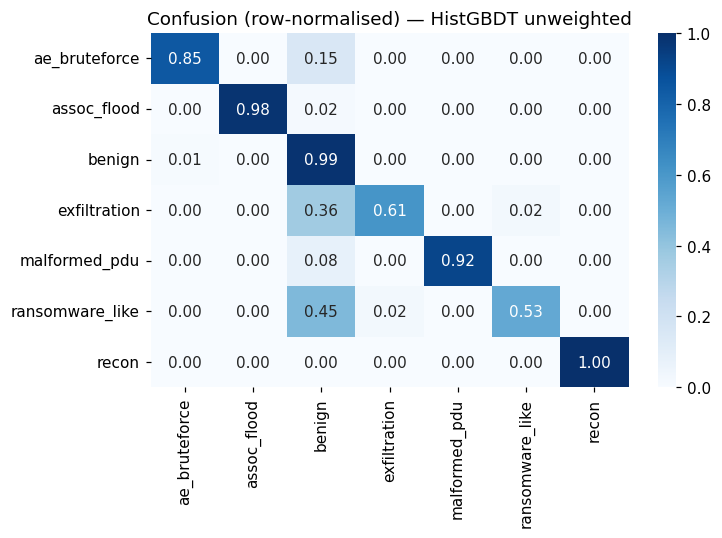

src_kind        attacker               compromised             
intensity           high    low   slow        high    low  slow
label_class                                                    
ae_bruteforce      100.0   97.0   74.6       100.0   87.8  82.5
assoc_flood         92.1  100.0  100.0        98.7  100.0  97.4
exfiltration        69.8   62.5   73.9        25.0   75.0  43.5
malformed_pdu      100.0  100.0   98.6        82.8  100.0  72.4
ransomware_like     73.9   42.9   25.0        81.0   50.0  45.4
recon              100.0  100.0  100.0       100.0  100.0   NaN

,sum,size,recall_%,CI95
label_class,,,,
ae_bruteforce,18,18,100.0,"(81.5, 100.0)"
assoc_flood,18,18,100.0,"(81.5, 100.0)"
exfiltration,11,18,61.1,"(35.7, 82.7)"
malformed_pdu,18,18,100.0,"(81.5, 100.0)"
ransomware_like,9,18,50.0,"(26.0, 74.0)"
recon,18,18,100.0,"(81.5, 100.0)"


[F44] best model macro-F1 | MCC on split_run test: HistGBDT unweighted: 0.883 | 0.876   (first EDA: RF 0.865 | 0.849)
[F45] LogReg macro-F1 after IAT fix: 0.77   (first EDA: 0.774 (seconds))
[F46] macro-F1 without recon (best): 0.863   (first EDA: not reported)
      -> report alongside macro-F1 (recon is trivial)
[F47] per-class F1 exfiltration | ransomware (best): 0.733 | 0.676   (first EDA: 0.684 | 0.526 (HistGBDT))
      -> weakest classes; confused with benign bulk C-STORE
[F48] FP per active vs wall-clock client-hour (best): 23.5 vs 2.0   (first EDA: 54.6 (RF, active-hour metric))
      -> deployment needs temporal smoothing (k-of-n windows)
[F49] no-size ablation macro-F1 (HistGBDT): 0.826   (first EDA: 0.826)
      -> result is not just a packet-size artefact


In [18]:
# Best-model diagnostics: confusion, recall by source x intensity, run-level recall with exact CIs
cm = np.nan_to_num(confusion_matrix(y[TE], pred, labels=list(range(len(CLS))), normalize="true"))
plt.figure(figsize=(7, 5)); sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLS, yticklabels=CLS)
plt.title(f"Confusion (row-normalised) — {best}"); savefig("confusion_best")

t = d[TE].assign(hit=(pred != BEN))
rec = t[t["label_class"] != "benign"].pivot_table(index="label_class", columns=["src_kind", "intensity"], values="hit", aggfunc="mean").mul(100).round(1)
display(rec)

def clopper(k, n, a=0.05):
    lo = beta.ppf(a / 2, k, n - k + 1) if k > 0 else 0.0
    hi = beta.ppf(1 - a / 2, k + 1, n - k) if k < n else 1.0
    return round(lo * 100, 1), round(hi * 100, 1)
MIN_FRAC = 0.5   # a run counts as detected only if >= 50% of its windows fire
rr = t[t["label_class"] != "benign"].groupby(["label_class", "attack_run"])["hit"].mean().ge(MIN_FRAC).groupby("label_class").agg(["sum", "size"])
rr["recall_%"] = (rr["sum"] / rr["size"] * 100).round(1); rr["CI95"] = [clopper(k, n) for k, n in zip(rr["sum"], rr["size"])]
display(rr)

finding("F44", "baselines", "best model macro-F1 | MCC on split_run test", f"{best}: {base.loc[best,'macro_F1']} | {base.loc[best,'MCC']}", "RF 0.865 | 0.849")
finding("F45", "baselines", "LogReg macro-F1 after IAT fix", base.loc["LogReg balanced", "macro_F1"], "0.774 (seconds)")
finding("F46", "baselines", "macro-F1 without recon (best)", base.loc[best, "macro_F1_no_recon"], "not reported", "report alongside macro-F1 (recon is trivial)")
finding("F47", "baselines", "per-class F1 exfiltration | ransomware (best)",
        f"{f1_score(y[TE]==CLS.index('exfiltration'), pred==CLS.index('exfiltration')):.3f} | {f1_score(y[TE]==CLS.index('ransomware_like'), pred==CLS.index('ransomware_like')):.3f}",
        "0.684 | 0.526 (HistGBDT)", "weakest classes; confused with benign bulk C-STORE")
finding("F48", "baselines", "FP per active vs wall-clock client-hour (best)", f"{base.loc[best,'FP_per_active_h']} vs {base.loc[best,'FP_per_wallclock_h']}",
        "54.6 (RF, active-hour metric)", "deployment needs temporal smoothing (k-of-n windows)")
finding("F49", "baselines", "no-size ablation macro-F1 (HistGBDT)", base.loc["HistGBDT no size feats", "macro_F1"], "0.826", "result is not just a packet-size artefact")

In [19]:
# Robustness of the best model family on the other protocols (trained on each split's train part)
def run_split(split_col, train_mask=None, test_mask=None):
    tr = (d[split_col] == "train").values if train_mask is None else train_mask
    te = (d[split_col] == "test").values if test_mask is None else test_mask
    mdl = RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=SEED).fit(d.loc[tr, ML_23_MS], y[tr])
    return round(f1_score(y[te], mdl.predict(d.loc[te, ML_23_MS]), average="macro"), 3)
camp = d["campaign_filled"].values; c_a, c_b = sorted(pd.unique(camp))[:2]
rob = {"split_site (test = unseen site)": run_split("split_site"), "split_time": run_split("split_time"),
       f"campaign {c_a} -> {c_b}": run_split("split_run", camp == c_a, camp == c_b),
       f"campaign {c_b} -> {c_a}": run_split("split_run", camp == c_b, camp == c_a)}
display(pd.Series(rob, name="RF macro-F1"))
finding("F50", "robustness", "RF macro-F1: site | time | campaign A->B | B->A", " | ".join(str(v) for v in rob.values()),
        "HistGBDT: 0.777 | n/a | 0.813 | 0.758", "generalisation gap to a new site/campaign is the main open problem")

split_site (test = unseen site)    0.865
split_time                         0.803
campaign run_0001 -> run_0002      0.768
campaign run_0002 -> run_0001      0.875
Name: RF macro-F1, dtype: float64

[F50] RF macro-F1: site | time | campaign A->B | B->A: 0.865 | 0.803 | 0.768 | 0.875   (first EDA: HistGBDT: 0.777 | n/a | 0.813 | 0.758)
      -> generalisation gap to a new site/campaign is the main open problem


## 14 · Feature engineering check (validation only, rolling computed inside each split partition)
Ratios, causal per-client rolling-3 means and `seq_count_in_win` — evaluated on `split_run` **val** with 3 seeds. Test is not touched here.

In [20]:
win["bytes_per_pkt"]      = (win["out_bytes"] + win["in_bytes"]) / (win["out_pkts"] + win["in_pkts"] + 1e-6)
win["out_in_byte_ratio"]  = win["out_bytes"] / (win["in_bytes"] + 1.0)
win["assoc_accept_ratio"] = win["assoc_ac"] / (win["assoc_rq"] + 1e-6)
win["rst_syn_ratio"]      = win["rst"] / (win["syn"] + 1e-6)
RATIO_FEATS = ["bytes_per_pkt", "out_in_byte_ratio", "assoc_accept_ratio", "rst_syn_ratio"]

ROLL_BASE = ["out_pkts", "out_bytes", "assoc_rq", "pdata_pkts", "mean_iat_ms"]
ROLL_FEATS = [f"{f}_roll3" for f in ROLL_BASE]
def add_rolling(frame, split_col="split_run"):
    # causal (past + current only), per client, never crossing a split partition (L12 fix)
    f = frame.sort_values(["client_ip", "window_start"]).copy()
    g = f.groupby([split_col, "client_ip"], sort=False)
    for b, r in zip(ROLL_BASE, ROLL_FEATS):
        f[r] = g[b].transform(lambda s: s.rolling(3, min_periods=1).mean())
    return f.sort_index()
win = add_rolling(win)

e = win[win["label_class"] != RULE_CLASS]
etr, eva = e["split_run"].eq("train").values, e["split_run"].eq("val").values
configs = {"ML_23 (ms)": ML_23_MS, "+ ratios": ML_23_MS + RATIO_FEATS,
           "+ ratios + roll3": ML_23_MS + RATIO_FEATS + ROLL_FEATS,
           "+ ratios + roll3 + seq_count (FINAL_33)": ML_23_MS + RATIO_FEATS + ROLL_FEATS + ["seq_count_in_win"]}
fe = {}
for name, cols in configs.items():
    for cw in ["balanced", None]:
        s = [f1_score(e.loc[eva, "label_class"], RandomForestClassifier(n_estimators=200, class_weight=cw, n_jobs=-1, random_state=k)
                      .fit(e.loc[etr, cols], e.loc[etr, "label_class"]).predict(e.loc[eva, cols]), average="macro") for k in range(3)]
        fe[(name, cw or "unweighted")] = f"{np.mean(s):.3f} ± {np.std(s):.3f}"
fe_tbl = pd.Series(fe).unstack(); display(fe_tbl)

# H3: polyglot from behaviour only (no http_post / preamble_exec)
p = win.copy(); ptr, pte = p["split_run"].eq("train").values, p["split_run"].eq("test").values
pm = RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=SEED).fit(p.loc[ptr, ML_23_MS], p.loc[ptr, "label_class"])
poly_f1 = f1_score(p.loc[pte, "label_class"] == RULE_CLASS, pm.predict(p.loc[pte, ML_23_MS]) == RULE_CLASS)

FINAL_33 = configs["+ ratios + roll3 + seq_count (FINAL_33)"]
finding("F51", "features", "val macro-F1 (RF, balanced): ML_23 -> FINAL_33", f"{fe_tbl.loc['ML_23 (ms)','balanced']} -> {fe_tbl.loc['+ ratios + roll3 + seq_count (FINAL_33)','balanced']}",
        "HistGBDT 0.866 -> 0.918 (rolling computed before split)", "adopt FINAL_33 if the gain holds with in-split rolling")
finding("F52", "features", "polyglot F1 from behaviour only (no http_post), split_run test", f"{poly_f1:.3f}", "not tested (kNN purity 90.6%)",
        "keep rule + test an ML class without http_post (hybrid)")

,balanced,unweighted
+ ratios,0.887 ± 0.001,0.891 ± 0.001
+ ratios + roll3,0.915 ± 0.001,0.919 ± 0.000
+ ratios + roll3 + seq_count (FINAL_33),0.914 ± 0.001,0.917 ± 0.001
ML_23 (ms),0.886 ± 0.000,0.889 ± 0.000


[F51] val macro-F1 (RF, balanced): ML_23 -> FINAL_33: 0.886 ± 0.000 -> 0.914 ± 0.001   (first EDA: HistGBDT 0.866 -> 0.918 (rolling computed before split))
      -> adopt FINAL_33 if the gain holds with in-split rolling
[F52] polyglot F1 from behaviour only (no http_post), split_run test: 0.980   (first EDA: not tested (kNN purity 90.6%))
      -> keep rule + test an ML class without http_post (hybrid)


## 15 · Export clean table, schema and findings

In [23]:
keep_meta = ["site","client_ip","window_start","attack_run","run_id","scenario_id","src_kind","intensity","campaign","campaign_filled",
             "label_class","label_binary","split_run","split_site","split_time","split_block","preamble_exec","http_post"]
flags = ["flag_dup_key","flag_label_conflict","flag_run_duration_outlier","flag_benign_like_in_attack"]
v2 = win[[c for c in keep_meta if c in win.columns] + sorted(set(ML_23_MS + RATIO_FEATS + ROLL_FEATS + ["seq_count_in_win"])) + flags]
v2.to_parquet(OUT / "windows_v2.parquet", index=False)

schema = {"ML_23_MS": ML_23_MS, "RATIO_FEATS": RATIO_FEATS, "ROLL_FEATS": ROLL_FEATS, "FINAL_33": FINAL_33,
          "SIZE_FEATS": SIZE_FEATS, "never_features": NEVER_FEATURES, "rule_class": RULE_CLASS, "flags": flags,
          "notes": {"iat": "mean_iat_ms/std_iat_ms = seconds*1000",
                    "rolling": "causal 3-window mean per client, computed within each split_run partition",
                    "primary_split": "split_run; robustness: split_site, split_time, cross-campaign; split_block rejected"}}
(OUT / "feature_schema.json").write_text(json.dumps(schema, indent=2, default=str), encoding="utf-8")

F = pd.DataFrame(FINDINGS); F["value"] = F["value"].astype(str)
F.to_csv(REP / "findings.csv", index=False, encoding="utf-8-sig")   # utf-8-sig so Excel shows ≈ correctly
try:
    md_text = F.to_markdown(index=False)
except ImportError:
    md_text = F.to_string(index=False)
(REP / "findings.md").write_text(md_text, encoding="utf-8")
print(f"saved: {OUT/'windows_v2.parquet'} {v2.shape}, feature_schema.json, findings ({len(F)})\n")
with pd.option_context("display.max_colwidth", 70):
    display(F[["id","topic","finding","value","first_eda"]])

saved: c:\Users\rashi\Desktop\VitalGate Project Code\data\processed\windows_v2.parquet (51933, 55), feature_schema.json, findings (52)



,id,topic,finding,value,first_eda
0,F01,integrity,windows / runs / sequences,"51,933 / 639 / 813,563","51,933 / 639 / 813,563"
1,F02,integrity,runs without sequences,3,3
2,F03,integrity,"duplicate (site, client_ip, window_start) keys",200 keys (400 rows),200 keys (400 rows)
3,F04,integrity,rows sharing an identical 24-feature vector,709,643
4,F05,integrity,feature patterns with >1 label (rows; attack rows),11 patterns (505 rows; 67 attack),11 patterns (505 rows; 67 attack)
5,F06,imbalance,imbalance max:min (runs | windows | sequences),1.10 | 35.5 | 160.9,1.10 | 35.5 | 160.9
6,F07,imbalance,recon share of sequences vs windows,23.0% vs 5.43%,23% vs 5.4%
7,F08,runs,runs with implausible duration (> 3x p90 of their intensity),0,"2 (≈8,605 s malformed_pdu slow; ≈8,620 s polyglot low)"
8,F09,distribution,features with |skew| > 3,21,21 of 24
9,F10,distribution,zero-inflation rst | syn | std_pkt (% zeros),91.7 | 20.9 | 10.0,91.7 | 20.9 | 10.0
